<a href="https://colab.research.google.com/github/klyoo/sds510/blob/main/SDS_510_Module_3_Basic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Module 3 Basics: Phoenix Crime Analysis**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "crimestat (1).csv",
    engine="python",
    on_bad_lines="skip"
)

df.head()

,INC NUMBER,OCCURRED ON,OCCURRED TO,UCR CRIME CATEGORY,100 BLOCK ADDR,ZIP,PREMISE TYPE
0,201600000052855,11/01/2015 00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE
1,201600000594484,11/01/2015 00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE
2,201500002102327,11/01/2015 00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT
3,201500002101405,11/01/2015 00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE
4,201500002102668,11/01/2015 00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE


In [ ]:
df.shape

(131676, 7)

**Analysis 1: Crime by ZIP code**

In [ ]:
crime_by_zip = df.groupby("ZIP").size()

crime_by_zip = crime_by_zip.sort_values(ascending=False)

crime_by_zip.head(10)

,0
ZIP,
85015.0,6963
85008.0,6320
85009.0,5513
85041.0,5477
85051.0,5389
85017.0,5355
85035.0,4752
85043.0,4331
85032.0,4301


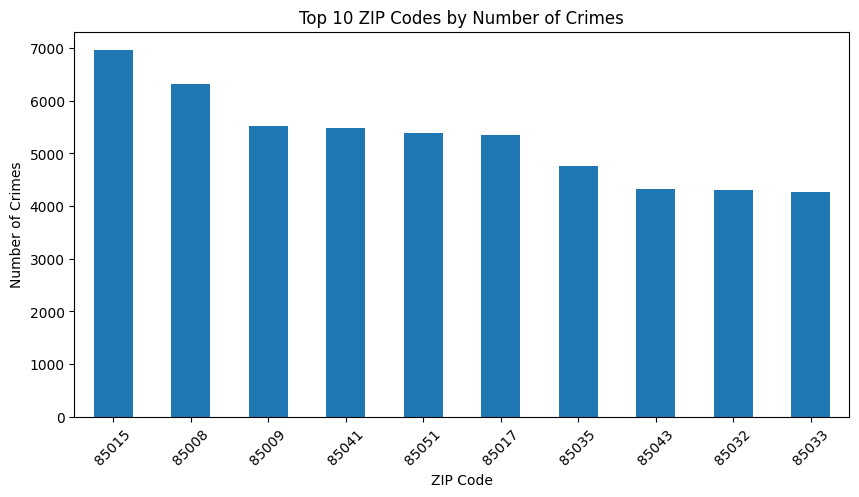

In [ ]:
crime_by_zip.head(10).rename(
    index=lambda x: str(int(x))
).plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 ZIP Codes by Number of Crimes")
plt.xlabel("ZIP Code")
plt.ylabel("Number of Crimes")
plt.xticks(rotation=45)
plt.show()

**Analysis 1 Results**

I used groupby() and size() to count the numbers of crime cases in each ZIP code. Then, I used sort_values() to identify the ZIP code that has highest number of crimes.

According to the plots, ZIP code 85015 has the most crime cases with 6963 cases, and the ZIP code 85008 has the second most crime cases with 6320.

**Analysis 2: Crime by category**

In [ ]:
crime_by_type = df["UCR CRIME CATEGORY"].value_counts()

crime_by_type

,count
UCR CRIME CATEGORY,
LARCENY-THEFT,66216
BURGLARY,23647
MOTOR VEHICLE THEFT,14391
DRUG OFFENSE,9572
AGGRAVATED ASSAULT,9306
ROBBERY,5640
RAPE,1981
ARSON,634
MURDER AND NON-NEGLIGENT MANSLAUGHTER,289


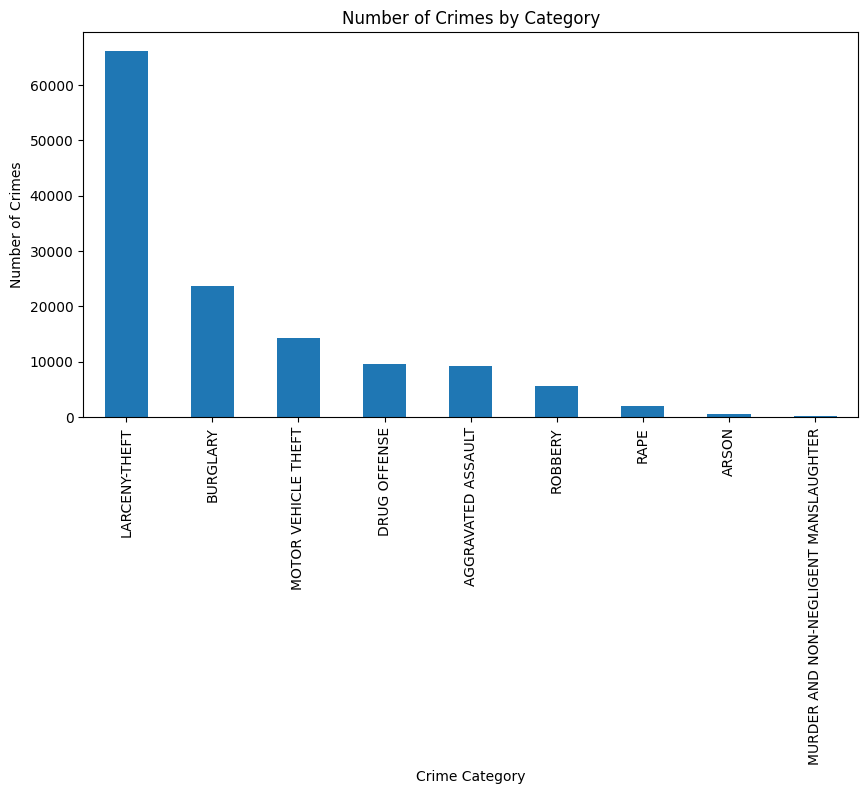

In [ ]:
crime_by_type.plot(kind="bar", figsize=(10, 5))

plt.title("Number of Crimes by Category")
plt.xlabel("Crime Category")
plt.ylabel("Number of Crimes")
plt.show()

**Analysis 2 Results**

I used value_counts() to count number of cases for each crime category.

According to the plots, the most common crime was Larceny-theft with 66216 cases, and the second most common category was burglary with 23647 cases.

**Analysis 3: 85015 ZIP code Crime Categories**

In [ ]:
crime_by_zip_type = df.groupby(
    ["ZIP", "UCR CRIME CATEGORY"]
).size()

crime_by_zip_type.head(20)

ZIP      UCR CRIME CATEGORY                   
85003.0  AGGRAVATED ASSAULT                        120
         ARSON                                       7
         BURGLARY                                  179
         DRUG OFFENSE                              194
         LARCENY-THEFT                             758
         MOTOR VEHICLE THEFT                       128
         MURDER AND NON-NEGLIGENT MANSLAUGHTER       2
         RAPE                                       47
         ROBBERY                                    78
85004.0  AGGRAVATED ASSAULT                        119
         ARSON                                       4
         BURGLARY                                  142
         DRUG OFFENSE                              114
         LARCENY-THEFT                            1007
         MOTOR VEHICLE THEFT                       126
         MURDER AND NON-NEGLIGENT MANSLAUGHTER       5
         RAPE                                       37
         ROBBERY                                    96
85006.0  AGGRAVATED ASSAULT                        248
         ARSON                                      20
dtype: int64

In [ ]:
crime_by_zip_type.loc[85015].sort_values(ascending=False)

,0
UCR CRIME CATEGORY,
LARCENY-THEFT,3636
BURGLARY,1140
DRUG OFFENSE,584
MOTOR VEHICLE THEFT,580
AGGRAVATED ASSAULT,476
ROBBERY,407
RAPE,80
ARSON,41
MURDER AND NON-NEGLIGENT MANSLAUGHTER,19


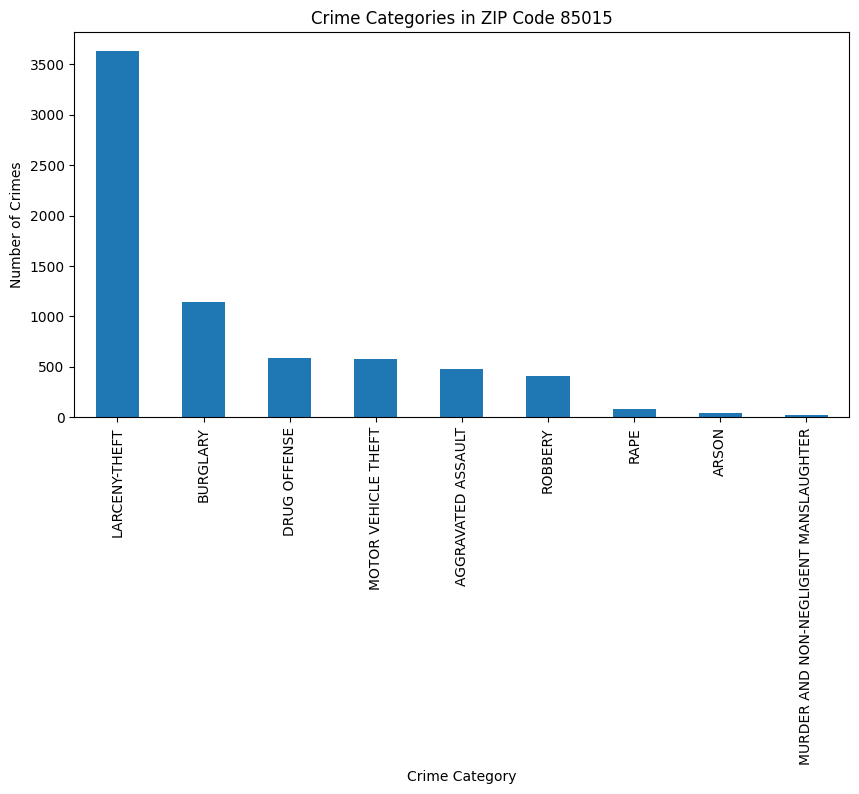

In [ ]:
crime_by_zip_type.loc[85015].sort_values(
    ascending=False
).plot(kind="bar", figsize=(10, 5))

plt.title("Crime Categories in ZIP Code 85015")
plt.xlabel("Crime Category")
plt.ylabel("Number of Crimes")
plt.show()

**Analysis 3 Results**

I used groupby() to group the data by ZIP code and crime category.

Since 85015 ZIP code had the most crime reports, I decided to analyze more about which crimes occurred the most in this ZIP code.

According to the plots, the most common crime in 85015 ZIP code was larceny-theft with 3636 cases, and the second most common crime was burglary with 1140 cases.

**Analysis 4: Violent cs. Non-violent Crimes**

In [ ]:
violent_crimes = [
    "AGGRAVATED ASSAULT",
    "ROBBERY",
    "RAPE",
    "MURDER AND NON-NEGLIGENT MANSLAUGHTER"
]

df["CRIME GROUP"] = "Non-violent"

df.loc[
    df["UCR CRIME CATEGORY"].isin(violent_crimes),
    "CRIME GROUP"
] = "Violent"

In [ ]:
crime_group_counts = df["CRIME GROUP"].value_counts()

crime_group_counts

,count
CRIME GROUP,
Non-violent,114460
Violent,17216


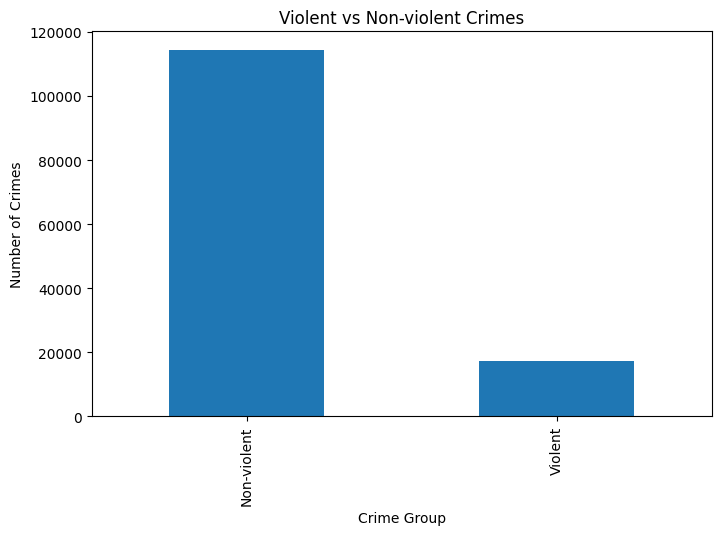

In [ ]:
crime_group_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Violent vs Non-violent Crimes")
plt.xlabel("Crime Group")
plt.ylabel("Number of Crimes")
plt.show()

**Analysis 4 Results**

I divided crime categories into two groups, violent and non-violent.

Violent crimes included aggravated assault, robbery, rape, and murder. And other categories were grouped as non-violent crimes.

I used isin() and loc[] to make two groups, violent and non-violent. And I used value_counts() to count the number of crime cases in each group.

According to the plots, there were 114460 non-violent crimes and 17216 violent crimes.